# 07 · Final comparison: one table, all five properties

Every model from notebooks 02–06, judged on the same test set and the same respelled copies of it:

| Property | Measure | Source |
|---|---|---|
| **Accuracy** | test weighted F1 (mean ± std over seeds) | notebooks 03, 04, 05, 06 |
| **Robustness** | F1 points lost when 100 % of eligible Hindi words are respelled (natural / rule) | notebooks 05, 06 |
| **Trust** | ECE as trained, ECE after temperature scaling, AURC (selective prediction) | notebooks 04, 05, 06 |
| **Size** | MB of saved weights | measured here |
| **Speed** | median CPU ms per tweet, batch size 1 | measured here, all in one session so the numbers are comparable |

Runs on the CPU in about 5 minutes. It reads the `results/0[4-6]_*.csv` files and times the saved checkpoints in `runs*/`.

In [1]:
import sys, json, pickle, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
RES, FIG_DIR = ROOT / "results", ROOT / "results/figures"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

from transformers import AutoTokenizer, AutoModelForSequenceClassification
from hinglish.data import load_splits
from hinglish.efficient import quantize_int8, size_mb, cpu_latency_ms

S = load_splits(ROOT / "data/processed"); te = S["test"]
ROWS = ["tfidf_lr", "tfidf_lr_aug", "mbert", "xlmr", "muril", "hingbert", "hingbert_aug",
        "teacher_int8", "teacher_trim", "student_nokd", "student_kd", "student_kd_int8"]
NAMES = {"tfidf_lr": "TF-IDF + LR", "tfidf_lr_aug": "TF-IDF + LR + spelling aug.", "mbert": "mBERT", "xlmr": "XLM-R",
         "muril": "MuRIL", "hingbert": "HingBERT", "hingbert_aug": "HingBERT + spelling aug. (teacher)",
         "teacher_int8": "Teacher, int8", "teacher_trim": "Teacher, trimmed vocab",
         "student_nokd": "Student 6L, no teacher", "student_kd": "Student 6L, distilled",
         "student_kd_int8": "Student 6L, distilled, int8 (final)"}

/Users/rahullalwani/Documents/IITMandi/Sem1/NLP/Project/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Accuracy, robustness and trust (from the saved results)

In [2]:
t04 = pd.read_csv(RES / "04_trust_runs.csv")
sel = pd.read_csv(RES / "04_selective_prediction.csv").set_index("model")
r05 = pd.read_csv(RES / "05_robust_runs.csv")
r06 = pd.read_csv(RES / "06_efficiency_runs.csv")
SEL_NAME = {"tfidf_lr": "TF-IDF + LR", "mbert": "mBERT", "xlmr": "XLM-R", "muril": "MuRIL",
            "hingbert": "HingBERT", "hingbert_aug": "HingBERT + aug"}

def drops(m):
    p = r05[r05.model == m].pivot_table(index="seed", columns="set", values="wF1")
    return ((p["natural 100%"] - p["clean"]) * 100).mean(), ((p["rule 100%"] - p["clean"]) * 100).mean(), len(p)

rows = {}
for m in ["tfidf_lr", "mbert", "xlmr", "muril", "hingbert", "hingbert_aug"]:
    t = t04[t04.model == m]
    nat, rule, n_rob = drops(m)
    rows[m] = {"wF1": t["test wF1"].mean(), "wF1 std": t["test wF1"].std() if len(t) > 1 else 0.0, "seeds": len(t),
               "drop natural": nat, "drop rule": rule, "robustness seeds": n_rob,
               "ECE": t["ECE before"].mean(), "ECE after T": t["ECE after"].mean(), "AURC": sel.loc[SEL_NAME[m], "AURC"]}
c = r05[(r05.model == "tfidf_lr_aug") & (r05.set == "clean")]
nat, rule, n_rob = drops("tfidf_lr_aug")
rows["tfidf_lr_aug"] = {"wF1": c.wF1.mean(), "wF1 std": 0.0, "seeds": 1, "drop natural": nat, "drop rule": rule,
                        "robustness seeds": n_rob, "ECE": c.ECE.mean(), "ECE after T": c["ECE after T"].mean(), "AURC": np.nan}
for v in ["teacher_int8", "teacher_trim", "student_nokd", "student_kd", "student_kd_int8"]:
    t = r06[r06.variant == v]
    rows[v] = {"wF1": t["wF1 clean"].mean(), "wF1 std": t["wF1 clean"].std() if len(t) > 1 else 0.0, "seeds": len(t),
               "drop natural": t["drop natural 100%"].mean(), "drop rule": t["drop rule 100%"].mean(), "robustness seeds": len(t),
               "ECE": t["ECE"].mean(), "ECE after T": t["ECE after T"].mean(), "AURC": t["AURC"].mean()}
quality = pd.DataFrame(rows).T.loc[ROWS]
quality.rename(index=NAMES).round(4)

,wF1,wF1 std,seeds,drop natural,drop rule,robustness seeds,ECE,ECE after T,AURC
TF-IDF + LR,0.6872,0.0000,1.0,-2.2730,-3.2804,1.0,0.0732,0.0605,0.1766
TF-IDF + LR + spelling aug.,0.6848,0.0000,1.0,-0.9411,-1.4244,1.0,0.0715,0.0578,NaN
mBERT,0.6803,0.0153,3.0,-2.1379,-3.1762,1.0,0.0388,0.0559,0.1799
XLM-R,0.7075,0.0083,3.0,-2.3174,-3.8591,1.0,0.0516,0.0650,0.1563
MuRIL,0.7042,0.0019,3.0,-2.5150,-2.5350,1.0,0.0358,0.0659,0.1774
HingBERT,0.7127,0.0027,3.0,-1.2070,-0.9421,3.0,0.1047,0.0490,0.1445
HingBERT + spelling aug. (teacher),0.7258,0.0071,3.0,-1.5543,-1.3191,3.0,0.0560,0.0492,0.1352
"Teacher, int8",0.7214,0.0000,1.0,-1.7657,-2.0579,1.0,0.0348,0.0475,0.1428
"Teacher, trimmed vocab",0.7200,0.0000,1.0,-2.3923,-1.6749,1.0,0.0792,0.0461,0.1406
"Student 6L, no teacher",0.7193,0.0068,3.0,-1.9788,-1.7426,3.0,0.0234,0.0677,0.1492


## 2. Size and CPU speed, all measured in this session

Transformers: the kept checkpoint of each model. TF-IDF: the fitted pipeline, pickled (vectoriser vocabulary + coefficients). The TF-IDF + augmentation pipeline has the same structure, so it is timed once.

In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline, make_union

C = json.loads((RES / "02_baseline_tfidf.json").read_text())["best_C"]
tfidf = make_pipeline(make_union(
    TfidfVectorizer(analyzer="word", ngram_range=(1, 2), min_df=2, sublinear_tf=True, lowercase=True),
    TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=3, sublinear_tf=True, lowercase=True, max_features=200_000)),
    LogisticRegression(C=C, max_iter=3000)).fit(S["train"].text, S["train"].label_id)
times = []
for t in te.text[:300]:
    t0 = time.perf_counter(); tfidf.predict_proba([t]); times.append((time.perf_counter() - t0) * 1000)
lr = tfidf[-1]
eff = {"tfidf_lr": {"parameters (M)": lr.coef_.size / 1e6, "size (MB)": len(pickle.dumps(tfidf)) / 2**20, "CPU ms / tweet": float(np.median(times))}}
eff["tfidf_lr_aug"] = dict(eff["tfidf_lr"])

def ckpt(path):
    return AutoModelForSequenceClassification.from_pretrained(path).eval(), AutoTokenizer.from_pretrained(path)

def first(pattern):
    return sorted(ROOT.glob(pattern))[0]

DIRS = {"mbert": first("runs/mbert/seed*/model"), "xlmr": first("runs/xlmr/seed*/model"),
        "muril": first("runs/muril/seed*/model"), "hingbert": first("runs/hingbert/seed*/model"),
        "hingbert_aug": ROOT / "runs_robust/aug/hingbert/seed43/model",
        "teacher_trim": ROOT / "runs_efficient/teacher_trimmed",
        "student_kd": ROOT / "runs_efficient/student_kd/seed42/model",
        "student_nokd": ROOT / "runs_efficient/student_nokd/seed42/model"}
for k, d in DIRS.items():
    m, tk = ckpt(d)
    eff[k] = {"parameters (M)": sum(p.numel() for p in m.parameters()) / 1e6, "size (MB)": size_mb(m),
              "CPU ms / tweet": cpu_latency_ms(m, tk, te.text, n=300)}
    if k in ("hingbert_aug", "student_kd"):
        q = quantize_int8(m); key = "teacher_int8" if k == "hingbert_aug" else "student_kd_int8"
        eff[key] = {"parameters (M)": eff[k]["parameters (M)"], "size (MB)": size_mb(q), "CPU ms / tweet": cpu_latency_ms(q, tk, te.text, n=300)}
    print(f"{NAMES[k]:40} {eff[k]['size (MB)']:7.1f} MB  {eff[k]['CPU ms / tweet']:6.2f} ms")
eff = pd.DataFrame(eff).T.loc[ROWS]

W1116 23:00:20.672000 64221 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 8939.29it/s]

mBERT                                      678.5 MB   21.95 ms


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 9537.90it/s]

... (16 outputs left out)

Student 6L, distilled                      204.5 MB    9.70 ms


Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 105/105 [00:00<00:00, 10836.93it/s]

Student 6L, no teacher                     204.5 MB    8.69 ms


## 3. The final table

In [4]:
final = eff.join(quality)
ref = final.loc["hingbert_aug"]
final["× smaller vs teacher"] = ref["size (MB)"] / final["size (MB)"]
final["× faster vs teacher"] = ref["CPU ms / tweet"] / final["CPU ms / tweet"]
cols = ["parameters (M)", "size (MB)", "CPU ms / tweet", "wF1", "wF1 std", "drop natural", "drop rule",
        "ECE", "ECE after T", "AURC", "seeds", "× smaller vs teacher", "× faster vs teacher"]
final = final[cols]
final.rename(index=NAMES).to_csv(RES / "07_final_table.csv")

def fmt(r):
    return {"Size": f"{r['size (MB)']:.0f} MB" if r['size (MB)'] >= 1 else f"{r['size (MB)']:.1f} MB",
            "CPU ms": f"{r['CPU ms / tweet']:.1f}",
            "Clean wF1": f"{r['wF1']:.3f}" + (f" ± {r['wF1 std']:.3f}" if r['seeds'] > 1 else ""),
            "Natural drop": f"{r['drop natural']:+.1f}", "Rule drop": f"{r['drop rule']:+.1f}",
            "ECE": f"{r['ECE']:.3f}", "ECE after T": f"{r['ECE after T']:.3f}",
            "AURC": "–" if pd.isna(r["AURC"]) else f"{r['AURC']:.3f}"}
pretty = pd.DataFrame({NAMES[k]: fmt(final.loc[k]) for k in ROWS}).T
display(pretty)
print("Drops in F1 points at 100 % respelling. mBERT, XLM-R and MuRIL robustness: best-validation checkpoint only; all other transformer rows: 3 seeds.")

,Size,CPU ms,Clean wF1,Natural drop,Rule drop,ECE,ECE after T,AURC
TF-IDF + LR,5 MB,0.5,0.687,-2.3,-3.3,0.073,0.061,0.177
TF-IDF + LR + spelling aug.,5 MB,0.5,0.685,-0.9,-1.4,0.072,0.058,–
mBERT,679 MB,21.9,0.680 ± 0.015,-2.1,-3.2,0.039,0.056,0.180
XLM-R,1061 MB,22.1,0.708 ± 0.008,-2.3,-3.9,0.052,0.065,0.156
MuRIL,906 MB,23.2,0.704 ± 0.002,-2.5,-2.5,0.036,0.066,0.177
HingBERT,418 MB,22.4,0.713 ± 0.003,-1.2,-0.9,0.105,0.049,0.145
HingBERT + spelling aug. (teacher),418 MB,22.6,0.726 ± 0.007,-1.6,-1.3,0.056,0.049,0.135
"Teacher, int8",173 MB,25.6,0.721,-1.8,-2.1,0.035,0.048,0.143
"Teacher, trimmed vocab",367 MB,17.6,0.720,-2.4,-1.7,0.079,0.046,0.141
"Student 6L, no teacher",205 MB,8.7,0.719 ± 0.007,-2.0,-1.7,0.023,0.068,0.149


Drops in F1 points at 100 % respelling. mBERT, XLM-R and MuRIL robustness: best-validation checkpoint only; all other transformer rows: 3 seeds.


### Markdown version (for the README and report)

In [5]:
print(pretty.to_markdown())

|                                     | Size    |   CPU ms | Clean wF1     |   Natural drop |   Rule drop |   ECE |   ECE after T | AURC   |
|:------------------------------------|:--------|---------:|:--------------|---------------:|------------:|------:|--------------:|:-------|
| TF-IDF + LR                         | 5 MB    |      0.5 | 0.687         |           -2.3 |        -3.3 | 0.073 |         0.061 | 0.177  |
| TF-IDF + LR + spelling aug.         | 5 MB    |      0.5 | 0.685         |           -0.9 |        -1.4 | 0.072 |         0.058 | –      |
| mBERT                               | 679 MB  |     21.9 | 0.680 ± 0.015 |           -2.1 |        -3.2 | 0.039 |         0.056 | 0.180  |
| XLM-R                               | 1061 MB |     22.1 | 0.708 ± 0.008 |           -2.3 |        -3.9 | 0.052 |         0.065 | 0.156  |
| MuRIL                               | 906 MB  |     23.2 | 0.704 ± 0.002 |           -2.5 |        -2.5 | 0.036 |         0.066 | 0.177  |
| HingBERT   

## 4. The trade-off in one figure

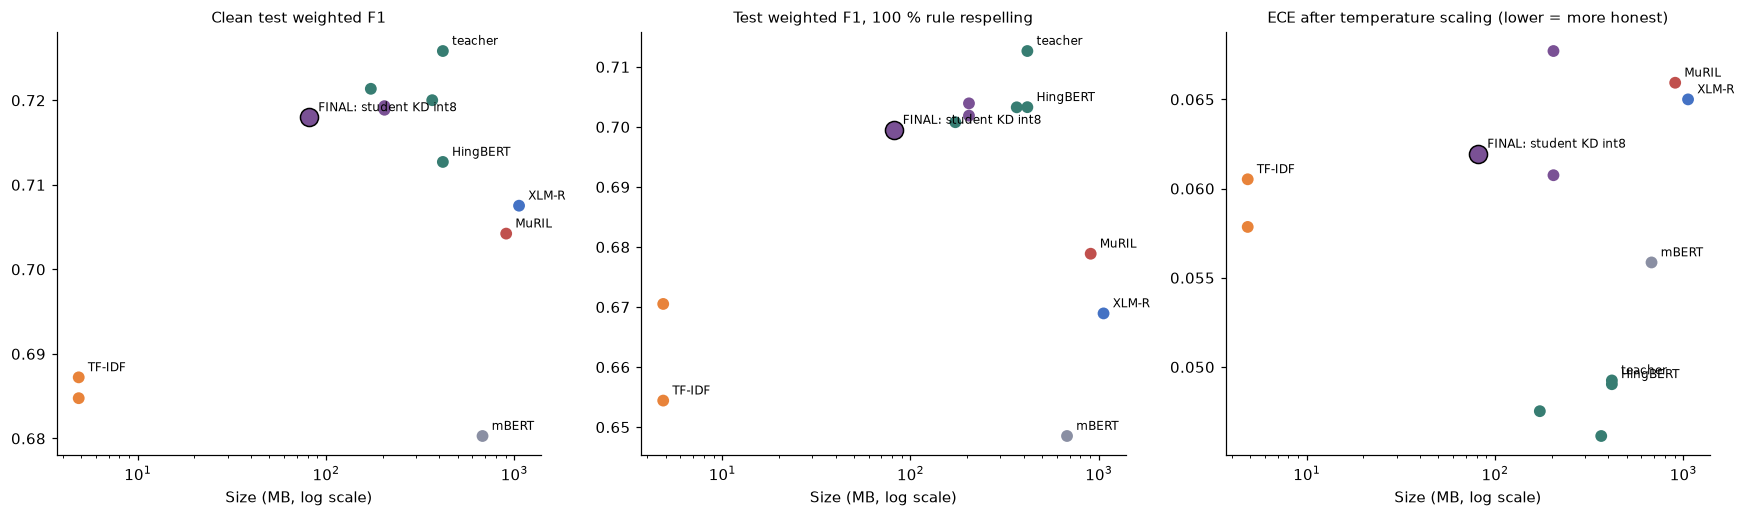

In [6]:
fam = {"tfidf_lr": "#E8833A", "tfidf_lr_aug": "#E8833A", "mbert": "#8A8FA3", "xlmr": "#4472C4", "muril": "#C0504D",
       "hingbert": "#377D72", "hingbert_aug": "#377D72", "teacher_int8": "#377D72", "teacher_trim": "#377D72",
       "student_nokd": "#7A5195", "student_kd": "#7A5195", "student_kd_int8": "#7A5195"}
SHORT = {"tfidf_lr": "TF-IDF", "tfidf_lr_aug": "TF-IDF+aug", "mbert": "mBERT", "xlmr": "XLM-R", "muril": "MuRIL",
         "hingbert": "HingBERT", "hingbert_aug": "teacher", "teacher_int8": "teacher int8", "teacher_trim": "teacher trim",
         "student_nokd": "student (no KD)", "student_kd": "student (KD)", "student_kd_int8": "FINAL: student KD int8"}
panels = [("wF1", "Clean test weighted F1", None),
          ("rule F1", "Test weighted F1, 100 % rule respelling", None),
          ("ECE after T", "ECE after temperature scaling (lower = more honest)", None)]
final["rule F1"] = final["wF1"] + final["drop rule"] / 100
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, (col, title, _) in zip(axes, panels):
    for k in ROWS:
        r = final.loc[k]
        big = k == "student_kd_int8"
        ax.scatter(r["size (MB)"], r[col], s=140 if big else 60, color=fam[k], edgecolor="black" if big else "none", zorder=3)
        if k in ("tfidf_lr", "mbert", "xlmr", "muril", "hingbert", "hingbert_aug", "student_kd_int8"):
            ax.annotate(SHORT[k], (r["size (MB)"], r[col]), textcoords="offset points", xytext=(6, 4), fontsize=8)
    ax.set_xscale("log"); ax.set_xlabel("Size (MB, log scale)"); ax.set_title(title, fontsize=10)
plt.tight_layout(); plt.savefig(FIG_DIR / "07_final_tradeoff.png"); plt.show()

## 5. Answer to the research question

**Can a Hinglish sentiment model be accurate, robust and honest, and stay that way once it is small and fast? Mostly yes.**

1. **Accuracy.** The final model (6-layer distilled HingBERT, trimmed vocabulary, int8) reaches **0.718 ± 0.006** test weighted F1. That is above every plain fine-tuned model (HingBERT 0.713, XLM-R 0.708, MuRIL 0.704, mBERT 0.680) and the TF-IDF baseline (0.687), and within 0.8 points of its 12-layer teacher (0.726).
2. **Efficiency.** It is **81 MB**: 5.1× smaller than the teacher and **13× smaller than XLM-R** (1,061 MB), which it beats on every column. It is 1.7× faster on CPU. int8 shrinks the model but does not speed it up on Apple silicon.
3. **Robustness.** Under 100 % respelling it loses 1.7 (natural) / 1.8 (rule) points, against 2.1–3.9 for mBERT, XLM-R, MuRIL and TF-IDF. Plain HingBERT is still the most robust (−1.2 / −0.9): pre-training on Hinglish matters more than anything we added. Spelling augmentation helped TF-IDF a lot (it halved the drop) but did not shrink HingBERT's.
4. **Trust.** As trained, the final model is better calibrated than its teacher (ECE 0.047 vs 0.056) and far better than plain HingBERT (0.105). After temperature scaling it reaches 0.062 vs 0.049: a small cost, and the only target it narrowly misses (≈ 0.05). Its AURC (0.148) is close to the teacher's (0.135) and better than every model except the HingBERT family.

**Does efficiency cost trust or robustness?** A little, but much less than choosing the wrong base model does. Compression from 418 MB to 81 MB costs about 0.8 F1, 0.5 points of robustness and 0.013 ECE after scaling. Choosing XLM-R instead of HingBERT costs about 2 F1, 2.6 points of robustness and 0.016 ECE, at 13× the size.

**What mattered most, in order:** (1) a model pre-trained on Hinglish (HingBERT); (2) spelling augmentation (+1.3 F1, overconfidence halved); (3) distillation for size and speed, at almost no accuracy cost.

**Limitations.** One dataset (SemEval-2020 SentiMix), so the val set is harder than test and temperature scaling transfers poorly. Respelling is synthetic, from mined variants and rules. Speeds are from one laptop CPU and vary ~30 % between sessions; the ratios are stable. Robustness for mBERT, XLM-R and MuRIL uses one checkpoint each.